Code to try out fitting gumbel distributions to my data... using linear approximations

In [ ]:
# --- data paths (see README: data layout) ---
import os
from pathlib import Path

# Root of the data store. Override with the DATA_ROOT environment variable.
DATA_ROOT = os.environ.get(
    "DATA_ROOT",
    "/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/AI-IFS-attributioncomparison/pnw2021",
)
# Root of this git repository (found by walking up from the working directory).
REPO = str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "scripts").is_dir()))


In [1]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import pandas as pd

from mystatsfunctions import LMoments

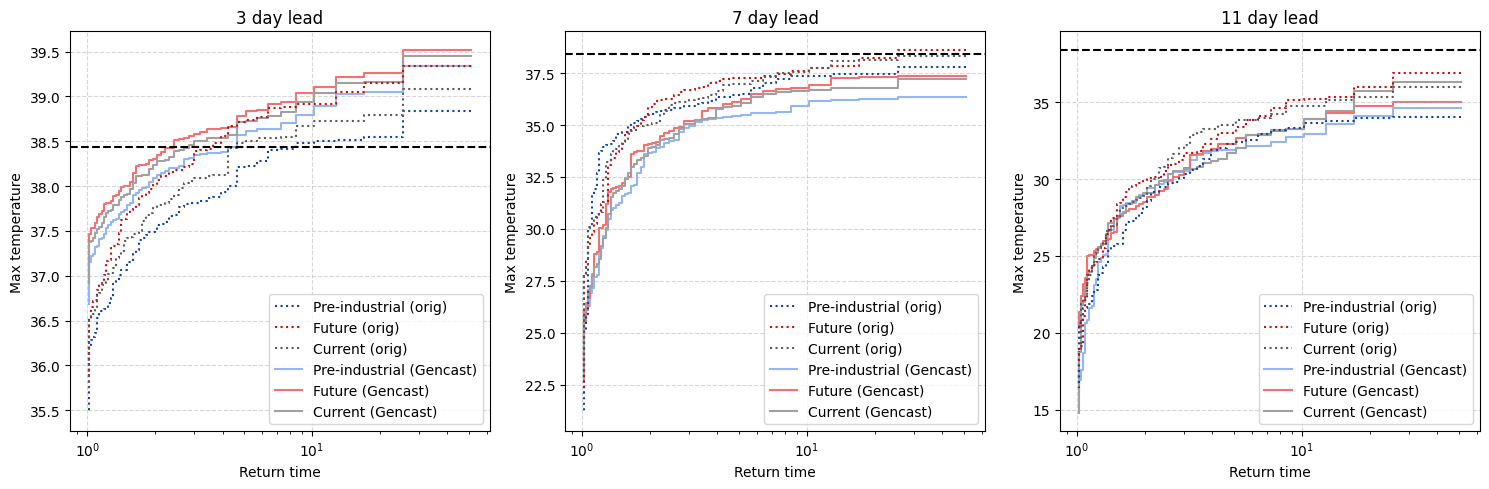

In [2]:
target_time = "2021-06-29T00:00:00"

pi_col_orig = "#0e42a3"
incr_col_orig = "#c90c0c"
oper_col_orig = "#595959"
pi_col_gencast = "#93b5f5"
incr_col_gencast = "#f56f6f"
oper_col_gencast = "#a0a0a0"
transparency = 0.99

def return_time(values):
    values = np.sort(values)[::-1]
    n = len(values)
    p = np.arange(1, n + 1) / (n + 1)
    return 1 / p, values

def ensemble_values_nc(ncfile):
    ds = xr.open_dataset(ncfile, decode_timedelta=True)
    da = ds["t2m"] - 273.15
    da = da.sel(time=target_time)

    if "latitude" in da.dims and "longitude" in da.dims:
        if float(da.latitude[0]) < float(da.latitude[-1]):
            da = da.sel(latitude=slice(45, 52), longitude=slice(-123, -119))
        else:
            da = da.sel(latitude=slice(52, 45), longitude=slice(-123, -119))
        da = da.mean(("latitude", "longitude"))

    return np.asarray(da.values).ravel()

def ensemble_values_zarr(zarrfile, init_time):
    ds = xr.open_zarr(zarrfile, consolidated=False)
    da = ds["2m_temperature"] - 273.15

    da = da.assign_coords(valid_time=("time", init_time + da["time"].values))
    da = da.swap_dims({"time": "valid_time"})
    da = da.sel(valid_time=target_time)

    if "lat" in da.dims:
        da = da.rename({"lat": "latitude"})
    if "lon" in da.dims:
        da = da.rename({"lon": "longitude"})

    if float(da.longitude.max()) > 180:
        da = da.assign_coords(longitude=((da.longitude + 180) % 360) - 180).sortby("longitude")

    if float(da.latitude[0]) < float(da.latitude[-1]):
        da = da.sel(latitude=slice(45, 52), longitude=slice(-123, -119))
    else:
        da = da.sel(latitude=slice(52, 45), longitude=slice(-123, -119))

    da = da.mean(("latitude", "longitude"))
    return np.asarray(da.values).ravel()

def exceedance_probability(vals, threshold):
    n = len(vals)
    nexceed = np.sum(vals >= threshold)

    if nexceed == 0:
        return f"< {1/n:.3f}", nexceed, n
    else:
        return f"{nexceed/n:.3f}", nexceed, n

def plot_panel(ax, orig_files, gencast_files, init_time, title):
    era5_ds = xr.open_dataset((DATA_ROOT + "/era5_pnw025_2021.nc"), decode_timedelta=True)
    era5_da = era5_ds["t2m"].sel(time=target_time) - 273.15
    era5_da = era5_da.sel(latitude=slice(52, 45), longitude=slice(-123, -119))
    era5_da = era5_da.mean(("latitude", "longitude"))
    threshold = float(era5_da.values)
    
    for info in orig_files.values():
        vals = ensemble_values_nc(info["file"])

        #prob, nexceed, n = exceedance_probability(vals, threshold)
        #print(f"{title:10s} | {info['label']:15s} | Original | "
        #      f"{nexceed}/{n} exceed | P = {prob}")

        rt, temp = return_time(vals)
        #ax.semilogx(
        #    rt, temp,
        #    linestyle="None",
        #    marker="o",
        #    color=info["color"],
        #    label=info["label"] + " (orig)"
        #)
        ax.plot(
        rt,
        temp,
        linestyle=":",
        drawstyle="steps-post",
        color=info["color"],
        label=info["label"] + " (orig)",
        alpha = transparency,
        zorder = 2
        )

    for info in gencast_files.values():
        vals = ensemble_values_zarr(info["file"], init_time)

        #prob, nexceed, n = exceedance_probability(vals, threshold)
        #print(f"{title:10s} | {info['label']:15s} | GenCast | "
        #      f"{nexceed}/{n} exceed | P = {prob}")

        rt, temp = return_time(vals)
        ax.plot(
        rt,
        temp,
        linestyle="-",
        drawstyle="steps-post",
        color=info["color"],
        label=info["label"] + " (Gencast)",
        alpha = transparency,
        zorder = 1
        )

    ax.axhline(threshold, color="black", linestyle="--")

    ax.set_title(title)
    ax.set_xlabel("Return time")
    ax.set_ylabel("Max temperature")

# -----------------------------
# Put your 3 lead-time cases here
# -----------------------------
panels = [
    {
        "title": "3 day lead",
        "init_time": np.datetime64("2021-06-26T00:00:00"),
        "orig_files": {
            "pi": {
                "file": "/network/group/aopp/predict/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/pi/pnw025/sfc/pf/b2mg_2021-06-26.nc",
                "label": "Pre-industrial",
                "color": pi_col_orig,
            },
            "incr": {
                "file": "/network/group/aopp/predict/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/incr/pnw025/sfc/pf/b2mh_2021-06-26.nc",
                "label": "Future",
                "color": incr_col_orig,
            },
            "oper": {
                "file": (DATA_ROOT + "/ifs/sfc/oper_pf_2021-06-26.nc"),
                "label": "Current",
                "color": oper_col_orig,
            },
        },
        "gencast_files": {
            "pi": {
                "file": (DATA_ROOT + "/gencast/predictions/1deg/pi/init-2021-06-26T00_10d/pred_1deg_pi_init-2021-06-26T00_10d_stitched_50ens.zarr"),
                "label": "Pre-industrial",
                "color": pi_col_gencast,
            },
            "incr": {
                "file": (DATA_ROOT + "/gencast/predictions/1deg/incr/init-2021-06-26T00_10d/pred_1deg_incr_init-2021-06-26T00_10d_stitched_50ens.zarr"),
                "label": "Future",
                "color": incr_col_gencast,
            },
            "oper": {
                "file": (DATA_ROOT + "/gencast/predictions/1deg/current/init-2021-06-26T00_10d/pred_1deg_current_init-2021-06-26T00_10d_stitched_50ens.zarr"),
                "label": "Current",
                "color": oper_col_gencast,
            },
        },
    },
    {
        "title": "7 day lead",
        "init_time": np.datetime64("2021-06-22T00:00:00"),
        "orig_files": {
            "pi": {
                "file": "/network/group/aopp/predict/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/pi/pnw025/sfc/pf/b2mg_2021-06-22.nc",
                "label": "Pre-industrial",
                "color": pi_col_orig,
            },
            "incr": {
                "file": "/network/group/aopp/predict/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/incr/pnw025/sfc/pf/b2mh_2021-06-22.nc",
                "label": "Future",
                "color": incr_col_orig,
            },
            "oper": {
                "file": (DATA_ROOT + "/ifs/sfc/oper_pf_2021-06-22.nc"),
                "label": "Current",
                "color": oper_col_orig,
            },
        },
        "gencast_files": {
            "pi": {
                "file": (DATA_ROOT + "/gencast/predictions/1deg/pi/init-2021-06-22T00_18d/pred_1deg_pi_init-2021-06-22T00_18d_stitched_50ens.zarr"),
                "label": "Pre-industrial",
                "color": pi_col_gencast,
            },
            "incr": {
                "file": (DATA_ROOT + "/gencast/predictions/1deg/incr/init-2021-06-22T00_18d/pred_1deg_incr_init-2021-06-22T00_18d_stitched_50ens.zarr"),
                "label": "Future",
                "color": incr_col_gencast,
            },
            "oper": {
                "file": (DATA_ROOT + "/gencast/predictions/1deg/current/init-2021-06-22T00_18d/pred_1deg_current_init-2021-06-22T00_18d_stitched_50ens.zarr"),
                "label": "Current",
                "color": oper_col_gencast,
            },
        },
    },
    {
        "title": "11 day lead",
        "init_time": np.datetime64("2021-06-18T00:00:00"),
        "orig_files": {
            "pi": {
                "file": "/network/group/aopp/archive02a/projects/predict/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/pi/pnw025/sfc/pf/b2mg_2021-06-18.nc",#b2mp_2021-06-18.nc",
                "label": "Pre-industrial",
                "color": pi_col_orig,
            },
            "incr": {
                "file": "/network/group/aopp/archive02a/projects/predict/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/incr/pnw025/sfc/pf/b2mh_2021-06-18.nc",#b2mq_2021-06-18.nc",
                "label": "Future",
                "color": incr_col_orig,
            },
            "oper": {
                "file": (DATA_ROOT + "/ifs/sfc/oper_pf_2021-06-18.nc"),#"/network/group/aopp/archive02a/projects/predict/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/ENS/pnw025/sfc/pf/b2mr_2021-06-18.nc",
                "label": "Current",
                "color": oper_col_orig,
            },
        },
        "gencast_files": {
            "pi": {
                "file": (DATA_ROOT + "/gencast/predictions/1deg/pi/init-2021-06-18T00_26d/pred_1deg_pi_init-2021-06-18T00_26d_stitched_50ens.zarr"),
                "label": "Pre-industrial",
                "color": pi_col_gencast,
            },
            "incr": {
                "file": (DATA_ROOT + "/gencast/predictions/1deg/incr/init-2021-06-18T00_26d/pred_1deg_incr_init-2021-06-18T00_26d_stitched_50ens.zarr"),
                "label": "Future",
                "color": incr_col_gencast,
            },
            "oper": {
                "file": (DATA_ROOT + "/gencast/predictions/1deg/current/init-2021-06-18T00_26d/pred_1deg_current_init-2021-06-18T00_26d_stitched_50ens.zarr"),
                "label": "Current",
                "color": oper_col_gencast,
            },
        },
    },
]

# -----------------------------
# Plot
# -----------------------------
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=False)

for ax, panel in zip(axes, panels):
    plot_panel(ax, panel["orig_files"], panel["gencast_files"], panel["init_time"], panel["title"])
    ax.legend(fontsize=8)
    #ax.set_ylim(30, 40)
    #axes[0].set_ylim(32.5, 41)
    #axes[1].set_ylim(32.5, 41)
    #axes[2].set_ylim(32.5, 40)
    ax.legend(loc='lower right')
    ax.set_xscale("log")
    ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

3 day lead: ERA5 mean = 38.43 °C, operational IFS std = 0.72 °C
7 day lead: ERA5 mean = 38.43 °C, operational IFS std = 3.08 °C
11 day lead: ERA5 mean = 38.43 °C, operational IFS std = 4.36 °C


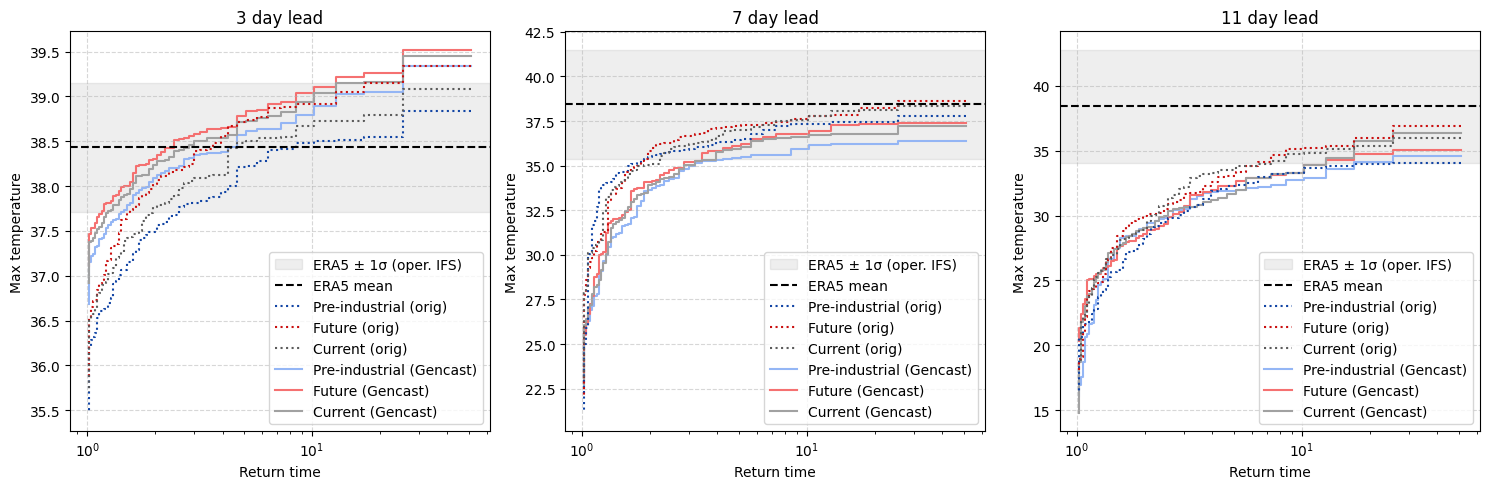

In [3]:
target_time = "2021-06-29T00:00:00"

pi_col_orig = "#0e42a3"
incr_col_orig = "#c90c0c"
oper_col_orig = "#595959"
pi_col_gencast = "#93b5f5"
incr_col_gencast = "#f56f6f"
oper_col_gencast = "#a0a0a0"
transparency = 0.99


def return_time(values):
    values = np.sort(values)[::-1]
    n = len(values)
    p = np.arange(1, n + 1) / (n + 1)
    return 1 / p, values


def ensemble_values_nc(ncfile):
    ds = xr.open_dataset(ncfile, decode_timedelta=True)
    da = ds["t2m"] - 273.15
    da = da.sel(time=target_time)

    if "latitude" in da.dims and "longitude" in da.dims:
        if float(da.latitude[0]) < float(da.latitude[-1]):
            da = da.sel(
                latitude=slice(45, 52),
                longitude=slice(-123, -119)
            )
        else:
            da = da.sel(
                latitude=slice(52, 45),
                longitude=slice(-123, -119)
            )

        da = da.mean(("latitude", "longitude"))

    return np.asarray(da.values).ravel()


def ensemble_values_zarr(zarrfile, init_time):
    ds = xr.open_zarr(zarrfile, consolidated=False)
    da = ds["2m_temperature"] - 273.15

    da = da.assign_coords(
        valid_time=("time", init_time + da["time"].values)
    )
    da = da.swap_dims({"time": "valid_time"})
    da = da.sel(valid_time=target_time)

    if "lat" in da.dims:
        da = da.rename({"lat": "latitude"})
    if "lon" in da.dims:
        da = da.rename({"lon": "longitude"})

    if float(da.longitude.max()) > 180:
        da = da.assign_coords(
            longitude=((da.longitude + 180) % 360) - 180
        ).sortby("longitude")

    if float(da.latitude[0]) < float(da.latitude[-1]):
        da = da.sel(
            latitude=slice(45, 52),
            longitude=slice(-123, -119)
        )
    else:
        da = da.sel(
            latitude=slice(52, 45),
            longitude=slice(-123, -119)
        )

    da = da.mean(("latitude", "longitude"))
    return np.asarray(da.values).ravel()


def exceedance_probability(vals, threshold):
    n = len(vals)
    nexceed = np.sum(vals >= threshold)

    if nexceed == 0:
        return f"< {1/n:.3f}", nexceed, n
    else:
        return f"{nexceed/n:.3f}", nexceed, n


def plot_panel(ax, orig_files, gencast_files, init_time, title):

    # ---------------------------------------------------
    # ERA5 mean over the PNW domain
    # ---------------------------------------------------
    era5_ds = xr.open_dataset(
        (DATA_ROOT + "/era5_pnw025_2021.nc"),
        decode_timedelta=True
    )

    era5_da = era5_ds["t2m"].sel(time=target_time) - 273.15
    era5_da = era5_da.sel(
        latitude=slice(52, 45),
        longitude=slice(-123, -119)
    )
    era5_da = era5_da.mean(("latitude", "longitude"))

    era5_mean = float(era5_da.values)

    # ---------------------------------------------------
    # Operational IFS ensemble spread at this lead time
    #
    # This is the standard deviation of the ORIGINAL
    # operational IFS ensemble at target_time.
    # ---------------------------------------------------
    oper_vals = ensemble_values_nc(orig_files["oper"]["file"])
    oper_std = np.std(oper_vals)

    print(
        f"{title}: ERA5 mean = {era5_mean:.2f} °C, "
        f"operational IFS std = {oper_std:.2f} °C"
    )    

    era5_lower = era5_mean - oper_std
    era5_upper = era5_mean + oper_std

    # ---------------------------------------------------
    # Plot shaded ERA5 +/- 1 operational IFS sigma band
    # ---------------------------------------------------
    ax.axhspan(
        era5_lower,
        era5_upper,
        color=oper_col_orig,
        alpha=0.1,
        zorder=0,
        label="ERA5 ± 1σ (oper. IFS)"
    )

    # ERA5 mean
    ax.axhline(
        era5_mean,
        color="black",
        linestyle="--",
        linewidth=1.5,
        zorder=3,
        label="ERA5 mean"
    )

    # ---------------------------------------------------
    # Original ensembles
    # ---------------------------------------------------
    for info in orig_files.values():

        vals = ensemble_values_nc(info["file"])

        # prob, nexceed, n = exceedance_probability(vals, era5_mean)
        # print(
        #     f"{title:10s} | {info['label']:15s} | Original | "
        #     f"{nexceed}/{n} exceed | P = {prob}"
        # )

        rt, temp = return_time(vals)

        ax.plot(
            rt,
            temp,
            linestyle=":",
            drawstyle="steps-post",
            color=info["color"],
            label=info["label"] + " (orig)",
            alpha=transparency,
            zorder=2
        )

    # ---------------------------------------------------
    # GenCast ensembles
    # ---------------------------------------------------
    for info in gencast_files.values():

        vals = ensemble_values_zarr(info["file"], init_time)

        # prob, nexceed, n = exceedance_probability(vals, era5_mean)
        # print(
        #     f"{title:10s} | {info['label']:15s} | GenCast | "
        #     f"{nexceed}/{n} exceed | P = {prob}"
        # )

        rt, temp = return_time(vals)

        ax.plot(
            rt,
            temp,
            linestyle="-",
            drawstyle="steps-post",
            color=info["color"],
            label=info["label"] + " (Gencast)",
            alpha=transparency,
            zorder=1
        )
        

    ax.set_title(title)
    ax.set_xlabel("Return time")
    ax.set_ylabel("Max temperature")


# -----------------------------
# Put your 3 lead-time cases here
# -----------------------------
panels = [
    {
        "title": "3 day lead",
        "init_time": np.datetime64("2021-06-26T00:00:00"),
        "orig_files": {
            "pi": {
                "file": "/network/group/aopp/predict/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/pi/pnw025/sfc/pf/b2mg_2021-06-26.nc",
                "label": "Pre-industrial",
                "color": pi_col_orig,
            },
            "incr": {
                "file": "/network/group/aopp/predict/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/incr/pnw025/sfc/pf/b2mh_2021-06-26.nc",
                "label": "Future",
                "color": incr_col_orig,
            },
            "oper": {
                "file": (DATA_ROOT + "/ifs/sfc/oper_pf_2021-06-26.nc"),
                "label": "Current",
                "color": oper_col_orig,
            },
        },
        "gencast_files": {
            "pi": {
                "file": (DATA_ROOT + "/gencast/predictions/1deg/pi/init-2021-06-26T00_10d/pred_1deg_pi_init-2021-06-26T00_10d_stitched_50ens.zarr"),
                "label": "Pre-industrial",
                "color": pi_col_gencast,
            },
            "incr": {
                "file": (DATA_ROOT + "/gencast/predictions/1deg/incr/init-2021-06-26T00_10d/pred_1deg_incr_init-2021-06-26T00_10d_stitched_50ens.zarr"),
                "label": "Future",
                "color": incr_col_gencast,
            },
            "oper": {
                "file": (DATA_ROOT + "/gencast/predictions/1deg/current/init-2021-06-26T00_10d/pred_1deg_current_init-2021-06-26T00_10d_stitched_50ens.zarr"),
                "label": "Current",
                "color": oper_col_gencast,
            },
        },
    },
    {
        "title": "7 day lead",
        "init_time": np.datetime64("2021-06-22T00:00:00"),
        "orig_files": {
            "pi": {
                "file": "/network/group/aopp/predict/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/pi/pnw025/sfc/pf/b2mg_2021-06-22.nc",
                "label": "Pre-industrial",
                "color": pi_col_orig,
            },
            "incr": {
                "file": "/network/group/aopp/predict/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/incr/pnw025/sfc/pf/b2mh_2021-06-22.nc",
                "label": "Future",
                "color": incr_col_orig,
            },
            "oper": {
                "file": (DATA_ROOT + "/ifs/sfc/oper_pf_2021-06-22.nc"),
                "label": "Current",
                "color": oper_col_orig,
            },
        },
        "gencast_files": {
            "pi": {
                "file": (DATA_ROOT + "/gencast/predictions/1deg/pi/init-2021-06-22T00_18d/pred_1deg_pi_init-2021-06-22T00_18d_stitched_50ens.zarr"),
                "label": "Pre-industrial",
                "color": pi_col_gencast,
            },
            "incr": {
                "file": (DATA_ROOT + "/gencast/predictions/1deg/incr/init-2021-06-22T00_18d/pred_1deg_incr_init-2021-06-22T00_18d_stitched_50ens.zarr"),
                "label": "Future",
                "color": incr_col_gencast,
            },
            "oper": {
                "file": (DATA_ROOT + "/gencast/predictions/1deg/current/init-2021-06-22T00_18d/pred_1deg_current_init-2021-06-22T00_18d_stitched_50ens.zarr"),
                "label": "Current",
                "color": oper_col_gencast,
            },
        },
    },
    {
        "title": "11 day lead",
        "init_time": np.datetime64("2021-06-18T00:00:00"),
        "orig_files": {
            "pi": {
                "file": "/network/group/aopp/archive02a/projects/predict/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/pi/pnw025/sfc/pf/b2mg_2021-06-18.nc",  # b2mp_2021-06-18.nc
                "label": "Pre-industrial",
                "color": pi_col_orig,
            },
            "incr": {
                "file": "/network/group/aopp/archive02a/projects/predict/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/incr/pnw025/sfc/pf/b2mh_2021-06-18.nc",  # b2mq_2021-06-18.nc
                "label": "Future",
                "color": incr_col_orig,
            },
            "oper": {
                "file": (DATA_ROOT + "/ifs/sfc/oper_pf_2021-06-18.nc"),  # "/network/group/aopp/archive02a/projects/predict/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/ENS/pnw025/sfc/pf/b2mr_2021-06-18.nc"
                "label": "Current",
                "color": oper_col_orig,
            },
        },
        "gencast_files": {
            "pi": {
                "file": (DATA_ROOT + "/gencast/predictions/1deg/pi/init-2021-06-18T00_26d/pred_1deg_pi_init-2021-06-18T00_26d_stitched_50ens.zarr"),
                "label": "Pre-industrial",
                "color": pi_col_gencast,
            },
            "incr": {
                "file": (DATA_ROOT + "/gencast/predictions/1deg/incr/init-2021-06-18T00_26d/pred_1deg_incr_init-2021-06-18T00_26d_stitched_50ens.zarr"),
                "label": "Future",
                "color": incr_col_gencast,
            },
            "oper": {
                "file": (DATA_ROOT + "/gencast/predictions/1deg/current/init-2021-06-18T00_26d/pred_1deg_current_init-2021-06-18T00_26d_stitched_50ens.zarr"),
                "label": "Current",
                "color": oper_col_gencast,
            },
        },
    },
]


# -----------------------------
# Plot
# -----------------------------
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=False)

for ax, panel in zip(axes, panels):
    plot_panel(
        ax,
        panel["orig_files"],
        panel["gencast_files"],
        panel["init_time"],
        panel["title"]
    )

    ax.legend(loc="lower right", fontsize=10)
    ax.set_xscale("log")
    ax.grid(True, linestyle="--", alpha=0.5)

    # Optional y-limits
    # ax.set_ylim(30, 40)
    # axes[0].set_ylim(32.5, 41)
    # axes[1].set_ylim(32.5, 41)
    # axes[2].set_ylim(32.5, 40)
    

plt.tight_layout()
plt.show()

3 day lead: ERA5 mean = 38.43 °C, operational IFS std = 0.72 °C
7 day lead: ERA5 mean = 38.43 °C, operational IFS std = 3.08 °C
11 day lead: ERA5 mean = 38.43 °C, operational IFS std = 4.36 °C


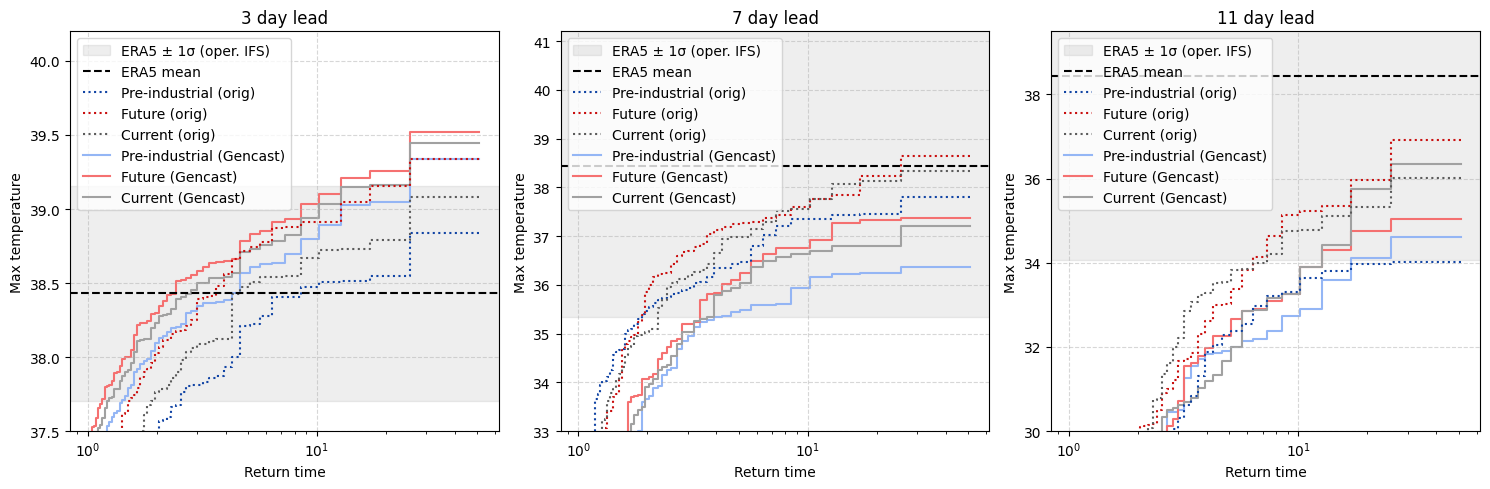

In [4]:
target_time = "2021-06-29T00:00:00"

pi_col_orig = "#0e42a3"
incr_col_orig = "#c90c0c"
oper_col_orig = "#595959"
pi_col_gencast = "#93b5f5"
incr_col_gencast = "#f56f6f"
oper_col_gencast = "#a0a0a0"
transparency = 0.99


def return_time(values):
    values = np.sort(values)[::-1]
    n = len(values)
    p = np.arange(1, n + 1) / (n + 1)
    return 1 / p, values


def ensemble_values_nc(ncfile):
    ds = xr.open_dataset(ncfile, decode_timedelta=True)
    da = ds["t2m"] - 273.15
    da = da.sel(time=target_time)

    if "latitude" in da.dims and "longitude" in da.dims:
        if float(da.latitude[0]) < float(da.latitude[-1]):
            da = da.sel(
                latitude=slice(45, 52),
                longitude=slice(-123, -119)
            )
        else:
            da = da.sel(
                latitude=slice(52, 45),
                longitude=slice(-123, -119)
            )

        da = da.mean(("latitude", "longitude"))

    return np.asarray(da.values).ravel()


def ensemble_values_zarr(zarrfile, init_time):
    ds = xr.open_zarr(zarrfile, consolidated=False)
    da = ds["2m_temperature"] - 273.15

    da = da.assign_coords(
        valid_time=("time", init_time + da["time"].values)
    )
    da = da.swap_dims({"time": "valid_time"})
    da = da.sel(valid_time=target_time)

    if "lat" in da.dims:
        da = da.rename({"lat": "latitude"})
    if "lon" in da.dims:
        da = da.rename({"lon": "longitude"})

    if float(da.longitude.max()) > 180:
        da = da.assign_coords(
            longitude=((da.longitude + 180) % 360) - 180
        ).sortby("longitude")

    if float(da.latitude[0]) < float(da.latitude[-1]):
        da = da.sel(
            latitude=slice(45, 52),
            longitude=slice(-123, -119)
        )
    else:
        da = da.sel(
            latitude=slice(52, 45),
            longitude=slice(-123, -119)
        )

    da = da.mean(("latitude", "longitude"))
    return np.asarray(da.values).ravel()


def exceedance_probability(vals, threshold):
    n = len(vals)
    nexceed = np.sum(vals >= threshold)

    if nexceed == 0:
        return f"< {1/n:.3f}", nexceed, n
    else:
        return f"{nexceed/n:.3f}", nexceed, n


def plot_panel(ax, orig_files, gencast_files, init_time, title):

    # ---------------------------------------------------
    # ERA5 mean over the PNW domain
    # ---------------------------------------------------
    era5_ds = xr.open_dataset(
        (DATA_ROOT + "/era5_pnw025_2021.nc"),
        decode_timedelta=True
    )

    era5_da = era5_ds["t2m"].sel(time=target_time) - 273.15
    era5_da = era5_da.sel(
        latitude=slice(52, 45),
        longitude=slice(-123, -119)
    )
    era5_da = era5_da.mean(("latitude", "longitude"))

    era5_mean = float(era5_da.values)

    # ---------------------------------------------------
    # Operational IFS ensemble spread at this lead time
    #
    # This is the standard deviation of the ORIGINAL
    # operational IFS ensemble at target_time.
    # ---------------------------------------------------
    oper_vals = ensemble_values_nc(orig_files["oper"]["file"])
    oper_std = np.std(oper_vals)

    print(
        f"{title}: ERA5 mean = {era5_mean:.2f} °C, "
        f"operational IFS std = {oper_std:.2f} °C"
    )    

    era5_lower = era5_mean - oper_std
    era5_upper = era5_mean + oper_std

    # ---------------------------------------------------
    # Plot shaded ERA5 +/- 1 operational IFS sigma band
    # ---------------------------------------------------
    ax.axhspan(
        era5_lower,
        era5_upper,
        color=oper_col_orig,
        alpha=0.1,
        zorder=0,
        label="ERA5 ± 1σ (oper. IFS)"
    )

    # ERA5 mean
    ax.axhline(
        era5_mean,
        color="black",
        linestyle="--",
        linewidth=1.5,
        zorder=3,
        label="ERA5 mean"
    )

    # ---------------------------------------------------
    # Original ensembles
    # ---------------------------------------------------
    for info in orig_files.values():

        vals = ensemble_values_nc(info["file"])

        # prob, nexceed, n = exceedance_probability(vals, era5_mean)
        # print(
        #     f"{title:10s} | {info['label']:15s} | Original | "
        #     f"{nexceed}/{n} exceed | P = {prob}"
        # )

        rt, temp = return_time(vals)

        ax.plot(
            rt,
            temp,
            linestyle=":",
            drawstyle="steps-post",
            color=info["color"],
            label=info["label"] + " (orig)",
            alpha=transparency,
            zorder=2
        )

    # ---------------------------------------------------
    # GenCast ensembles
    # ---------------------------------------------------
    for info in gencast_files.values():

        vals = ensemble_values_zarr(info["file"], init_time)

        # prob, nexceed, n = exceedance_probability(vals, era5_mean)
        # print(
        #     f"{title:10s} | {info['label']:15s} | GenCast | "
        #     f"{nexceed}/{n} exceed | P = {prob}"
        # )

        rt, temp = return_time(vals)

        ax.plot(
            rt,
            temp,
            linestyle="-",
            drawstyle="steps-post",
            color=info["color"],
            label=info["label"] + " (Gencast)",
            alpha=transparency,
            zorder=1
        )
        

    ax.set_title(title)
    ax.set_xlabel("Return time")
    ax.set_ylabel("Max temperature")


# -----------------------------
# Put your 3 lead-time cases here
# -----------------------------
panels = [
    {
        "title": "3 day lead",
        "init_time": np.datetime64("2021-06-26T00:00:00"),
        "orig_files": {
            "pi": {
                "file": "/network/group/aopp/predict/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/pi/pnw025/sfc/pf/b2mg_2021-06-26.nc",
                "label": "Pre-industrial",
                "color": pi_col_orig,
            },
            "incr": {
                "file": "/network/group/aopp/predict/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/incr/pnw025/sfc/pf/b2mh_2021-06-26.nc",
                "label": "Future",
                "color": incr_col_orig,
            },
            "oper": {
                "file": (DATA_ROOT + "/ifs/sfc/oper_pf_2021-06-26.nc"),
                "label": "Current",
                "color": oper_col_orig,
            },
        },
        "gencast_files": {
            "pi": {
                "file": (DATA_ROOT + "/gencast/predictions/1deg/pi/init-2021-06-26T00_10d/pred_1deg_pi_init-2021-06-26T00_10d_stitched_50ens.zarr"),
                "label": "Pre-industrial",
                "color": pi_col_gencast,
            },
            "incr": {
                "file": (DATA_ROOT + "/gencast/predictions/1deg/incr/init-2021-06-26T00_10d/pred_1deg_incr_init-2021-06-26T00_10d_stitched_50ens.zarr"),
                "label": "Future",
                "color": incr_col_gencast,
            },
            "oper": {
                "file": (DATA_ROOT + "/gencast/predictions/1deg/current/init-2021-06-26T00_10d/pred_1deg_current_init-2021-06-26T00_10d_stitched_50ens.zarr"),
                "label": "Current",
                "color": oper_col_gencast,
            },
        },
    },
    {
        "title": "7 day lead",
        "init_time": np.datetime64("2021-06-22T00:00:00"),
        "orig_files": {
            "pi": {
                "file": "/network/group/aopp/predict/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/pi/pnw025/sfc/pf/b2mg_2021-06-22.nc",
                "label": "Pre-industrial",
                "color": pi_col_orig,
            },
            "incr": {
                "file": "/network/group/aopp/predict/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/incr/pnw025/sfc/pf/b2mh_2021-06-22.nc",
                "label": "Future",
                "color": incr_col_orig,
            },
            "oper": {
                "file": (DATA_ROOT + "/ifs/sfc/oper_pf_2021-06-22.nc"),
                "label": "Current",
                "color": oper_col_orig,
            },
        },
        "gencast_files": {
            "pi": {
                "file": (DATA_ROOT + "/gencast/predictions/1deg/pi/init-2021-06-22T00_18d/pred_1deg_pi_init-2021-06-22T00_18d_stitched_50ens.zarr"),
                "label": "Pre-industrial",
                "color": pi_col_gencast,
            },
            "incr": {
                "file": (DATA_ROOT + "/gencast/predictions/1deg/incr/init-2021-06-22T00_18d/pred_1deg_incr_init-2021-06-22T00_18d_stitched_50ens.zarr"),
                "label": "Future",
                "color": incr_col_gencast,
            },
            "oper": {
                "file": (DATA_ROOT + "/gencast/predictions/1deg/current/init-2021-06-22T00_18d/pred_1deg_current_init-2021-06-22T00_18d_stitched_50ens.zarr"),
                "label": "Current",
                "color": oper_col_gencast,
            },
        },
    },
    {
        "title": "11 day lead",
        "init_time": np.datetime64("2021-06-18T00:00:00"),
        "orig_files": {
            "pi": {
                "file": "/network/group/aopp/archive02a/projects/predict/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/pi/pnw025/sfc/pf/b2mg_2021-06-18.nc",  # b2mp_2021-06-18.nc
                "label": "Pre-industrial",
                "color": pi_col_orig,
            },
            "incr": {
                "file": "/network/group/aopp/archive02a/projects/predict/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/incr/pnw025/sfc/pf/b2mh_2021-06-18.nc",  # b2mq_2021-06-18.nc
                "label": "Future",
                "color": incr_col_orig,
            },
            "oper": {
                "file": (DATA_ROOT + "/ifs/sfc/oper_pf_2021-06-18.nc"),  # "/network/group/aopp/archive02a/projects/predict/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/ENS/pnw025/sfc/pf/b2mr_2021-06-18.nc"
                "label": "Current",
                "color": oper_col_orig,
            },
        },
        "gencast_files": {
            "pi": {
                "file": (DATA_ROOT + "/gencast/predictions/1deg/pi/init-2021-06-18T00_26d/pred_1deg_pi_init-2021-06-18T00_26d_stitched_50ens.zarr"),
                "label": "Pre-industrial",
                "color": pi_col_gencast,
            },
            "incr": {
                "file": (DATA_ROOT + "/gencast/predictions/1deg/incr/init-2021-06-18T00_26d/pred_1deg_incr_init-2021-06-18T00_26d_stitched_50ens.zarr"),
                "label": "Future",
                "color": incr_col_gencast,
            },
            "oper": {
                "file": (DATA_ROOT + "/gencast/predictions/1deg/current/init-2021-06-18T00_26d/pred_1deg_current_init-2021-06-18T00_26d_stitched_50ens.zarr"),
                "label": "Current",
                "color": oper_col_gencast,
            },
        },
    },
]


# -----------------------------
# Plot
# -----------------------------
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=False)

for ax, panel in zip(axes, panels):
    plot_panel(
        ax,
        panel["orig_files"],
        panel["gencast_files"],
        panel["init_time"],
        panel["title"]
    )

    ax.legend(loc="upper left", fontsize=10)
    ax.set_xscale("log")
    ax.grid(True, linestyle="--", alpha=0.5)

    # Optional y-limits
    # ax.set_ylim(30, 40)
    axes[0].set_ylim(37.5, 40.2)
    axes[1].set_ylim(33, 41.2)
    axes[2].set_ylim(30, 39.5)
    

plt.tight_layout()
plt.show()

In [ ]:
# -------------------------------------------------------
# Count members above (ERA5 - 1 std of operational IFS)
# -------------------------------------------------------

def era5_value():
    era5_ds = xr.open_dataset(
        (DATA_ROOT + "/era5_pnw025_2021.nc"),
        decode_timedelta=True
    )
    da = era5_ds["t2m"].sel(time=target_time) - 273.15
    da = da.sel(
        latitude=slice(52, 45),
        longitude=slice(-123, -119)
    )
    da = da.mean(("latitude", "longitude"))
    return float(da.values)


era5 = era5_value()

print(f"ERA5 mean = {era5:.2f} °C\n")


for panel in panels:

    print("=" * 60)
    print(panel["title"])
    print("=" * 60)

    # ---------------------------------------------------
    # Operational IFS ensemble spread at this lead time
    # ---------------------------------------------------
    oper_vals = ensemble_values_nc(panel["orig_files"]["oper"]["file"])
    oper_std = np.std(oper_vals)

    threshold = era5 - oper_std

    print(
        f"ERA5 mean = {era5:.2f} °C | "
        f"operational IFS σ = {oper_std:.2f} °C"
    )

    print(
        f"ERA5 - 1σ threshold = {threshold:.2f} °C\n"
    )

    # ---------------------------------------------------
    # Count ORIGINAL members above ERA5 - 1 sigma
    # ---------------------------------------------------
    print("Original")

    for key, info in panel["orig_files"].items():

        vals = ensemble_values_nc(info["file"])

        n = len(vals)
        nexceed = np.sum(vals >= threshold)

        print(
            f"{info['label']:15s}: "
            f"{nexceed:2d}/{n:2d} "
            f"({100*nexceed/n:5.1f}%)"
        )

    print()

    # ---------------------------------------------------
    # Count GenCast members above ERA5 - 1 sigma
    # ---------------------------------------------------
    print("GenCast")

    for key, info in panel["gencast_files"].items():

        vals = ensemble_values_zarr(
            info["file"],
            panel["init_time"]
        )

        n = len(vals)
        nexceed = np.sum(vals >= threshold)

        print(
            f"{info['label']:15s}: "
            f"{nexceed:2d}/{n:2d} "
            f"({100*nexceed/n:5.1f}%)"
        )

    print()

ERA5 mean = 38.43 °C

3 day lead
ERA5 mean = 38.43 °C | operational IFS σ = 0.72 °C
ERA5 - 1σ threshold = 37.71 °C

Original
Pre-industrial : 19/50 ( 38.0%)
Future         : 32/50 ( 64.0%)
Current        : 25/50 ( 50.0%)

GenCast
Pre-industrial : 35/50 ( 70.0%)
Future         : 43/50 ( 86.0%)
Current        : 40/50 ( 80.0%)

7 day lead
ERA5 mean = 38.43 °C | operational IFS σ = 3.08 °C
ERA5 - 1σ threshold = 35.35 °C

Original
Pre-industrial : 26/50 ( 52.0%)
Future         : 26/50 ( 52.0%)
Current        : 22/50 ( 44.0%)

GenCast
Pre-industrial : 11/50 ( 22.0%)
Future         : 14/50 ( 28.0%)
Current        : 12/50 ( 24.0%)

11 day lead
ERA5 mean = 38.43 °C | operational IFS σ = 4.36 °C
ERA5 - 1σ threshold = 34.07 °C

Original
Pre-industrial :  0/50 (  0.0%)
Future         :  7/50 ( 14.0%)
Current        :  6/50 ( 12.0%)

GenCast
Pre-industrial :  2/50 (  4.0%)
Future         :  3/50 (  6.0%)
Current        :  3/50 (  6.0%)




3 day lead: ERA5 = 38.43 °C, fitting quintile 2/5 (hottest = 1)
Pre-industrial  IFS: T = 37.325 + 0.423 ln(R)
Future          IFS: T = 37.380 + 0.822 ln(R)
Current         IFS: T = 37.386 + 0.585 ln(R)
Pre-industrial  GenCast: T = 37.921 + 0.338 ln(R)
Future          GenCast: T = 38.262 + 0.271 ln(R)
Current         GenCast: T = 38.126 + 0.298 ln(R)

7 day lead: ERA5 = 38.43 °C, fitting quintile 1/5 (hottest = 1)
Pre-industrial  IFS: T = 35.821 + 0.541 ln(R)
Future          IFS: T = 36.149 + 0.628 ln(R)
Current         IFS: T = 36.032 + 0.638 ln(R)
Pre-industrial  GenCast: T = 34.766 + 0.452 ln(R)
Future          GenCast: T = 35.424 + 0.563 ln(R)
Current         GenCast: T = 35.431 + 0.464 ln(R)

11 day lead: ERA5 = 38.43 °C, fitting quintile 1/5 (hottest = 1)
Pre-industrial  IFS: T = 31.252 + 0.809 ln(R)
Future          IFS: T = 30.917 + 1.585 ln(R)
Current         IFS: T = 31.976 + 1.059 ln(R)
Pre-industrial  GenCast: T = 29.769 + 1.277 ln(R)
Future          GenCast: T = 30.475 + 1.

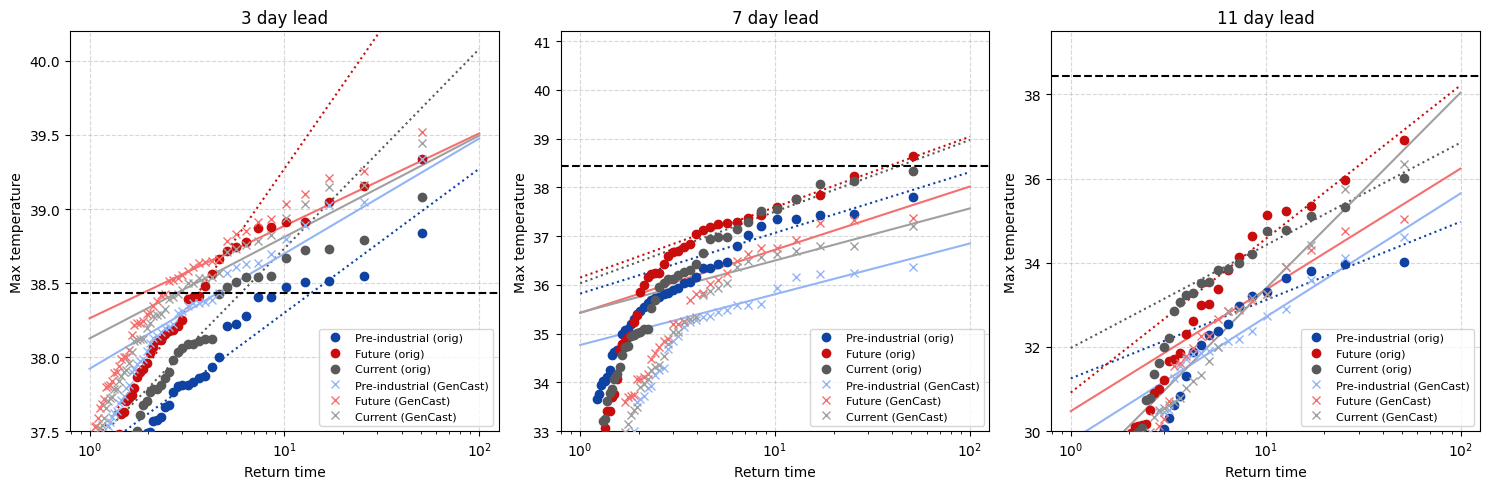

In [ ]:
# -------------------------------------------------------
# Return time
# -------------------------------------------------------
def return_time(values):
    values = np.asarray(values)
    values = values[np.isfinite(values)]
    values = np.sort(values)[::-1]

    n = len(values)
    p = np.arange(1, n + 1) / (n + 1)

    return 1 / p, values


# -------------------------------------------------------
# Which quintile of the operational IFS is closest
# to the event threshold?
#
# Quintile 1 = hottest 20%
# Quintile 5 = coolest 20%
# -------------------------------------------------------
def find_operational_quintile(oper_vals, threshold):

    vals = np.sort(
        np.asarray(oper_vals)[np.isfinite(oper_vals)]
    )[::-1]  # hottest -> coolest

    groups = np.array_split(vals, 5)

    # Distance from ERA5 threshold to each quintile
    distances = []

    for group in groups:
        if threshold > group.max():
            distance = threshold - group.max()
        elif threshold < group.min():
            distance = group.min() - threshold
        else:
            distance = 0

        distances.append(distance)

    return np.argmin(distances)


# -------------------------------------------------------
# Fit T = a + b ln(R)
#
# quintile 0 = hottest 20%
# quintile 1 = next 20%
# ...
# quintile 4 = coolest 20%
# -------------------------------------------------------
def fit_tail_line(vals, quintile):

    vals = np.asarray(vals)
    vals = vals[np.isfinite(vals)]

    rt, temp = return_time(vals)

    n = len(vals)
    edges = np.linspace(0, n, 6).astype(int)

    start = edges[quintile]
    end = edges[quintile + 1]

    rt_fit = rt[start:end]
    temp_fit = temp[start:end]

    b, a = np.polyfit(
        np.log(rt_fit),
        temp_fit,
        1
    )

    return a, b, rt_fit, temp_fit


# -------------------------------------------------------
# Plot
# -------------------------------------------------------
def plot_panel(ax, orig_files, gencast_files, init_time, title):

    # ---------------------------------------------------
    # ERA5 event temperature
    # ---------------------------------------------------
    era5_ds = xr.open_dataset(
        (DATA_ROOT + "/era5_pnw025_2021.nc"),
        decode_timedelta=True
    )

    era5_da = era5_ds["t2m"].sel(time=target_time) - 273.15

    era5_da = era5_da.sel(
        latitude=slice(52, 45),
        longitude=slice(-123, -119)
    )

    era5_da = era5_da.mean(
        ("latitude", "longitude")
    )

    threshold = float(era5_da.values)

    # ---------------------------------------------------
    # Find relevant quintile from operational IFS
    # ---------------------------------------------------
    oper_vals = ensemble_values_nc(
        orig_files["oper"]["file"]
    )

    quintile = find_operational_quintile(
        oper_vals,
        threshold
    )

    print(
        f"\n{title}: ERA5 = {threshold:.2f} °C, "
        f"fitting quintile {quintile + 1}/5 "
        f"(hottest = 1)"
    )

    # ---------------------------------------------------
    # Original IFS
    # ---------------------------------------------------
    for info in orig_files.values():

        vals = ensemble_values_nc(info["file"])

        rt, temp = return_time(vals)

        # Plot ALL members
        ax.plot(
            rt,
            temp,
            linestyle="None",
            marker="o",
            color=info["color"],
            label=info["label"] + " (orig)",
            zorder=3
        )

        # Fit ONLY the selected quintile
        a, b, rt_fit, temp_fit = fit_tail_line(
            vals,
            quintile
        )

        # Plot fitted line over full range
        rt_line = np.logspace(0, 2, 300)
        temp_line = a + b * np.log(rt_line)

        ax.plot(
            rt_line,
            temp_line,
            color=info["color"],
            linestyle=":",
            linewidth=1.5,
            zorder=2
        )

        print(
            f"{info['label']:15s} IFS: "
            f"T = {a:.3f} + {b:.3f} ln(R)"
        )

    # ---------------------------------------------------
    # GenCast
    # ---------------------------------------------------
    for info in gencast_files.values():

        vals = ensemble_values_zarr(
            info["file"],
            init_time
        )

        rt, temp = return_time(vals)

        # Plot ALL members
        ax.plot(
            rt,
            temp,
            linestyle="None",
            marker="x",
            color=info["color"],
            label=info["label"] + " (GenCast)",
            zorder=3
        )

        # Fit SAME QUINTILE NUMBER
        a, b, rt_fit, temp_fit = fit_tail_line(
            vals,
            quintile
        )

        # Plot fitted line over full range
        rt_line = np.logspace(0, 2, 300)
        temp_line = a + b * np.log(rt_line)

        ax.plot(
            rt_line,
            temp_line,
            color=info["color"],
            linestyle="-",
            linewidth=1.5,
            zorder=2
        )

        print(
            f"{info['label']:15s} GenCast: "
            f"T = {a:.3f} + {b:.3f} ln(R)"
        )

    # ---------------------------------------------------
    # Event threshold
    # ---------------------------------------------------
    ax.axhline(
        threshold,
        color="black",
        linestyle="--",
        zorder=4
    )

    ax.set_title(title)
    ax.set_xlabel("Return time")
    ax.set_ylabel("Max temperature")
    ax.set_xscale("log")
    ax.grid(True, linestyle="--", alpha=0.5)


# -------------------------------------------------------
# Plot all lead times
# -------------------------------------------------------
fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 5),
    sharey=False
)

for ax, panel in zip(axes, panels):

    plot_panel(
        ax,
        panel["orig_files"],
        panel["gencast_files"],
        panel["init_time"],
        panel["title"]
    )

    #ax.set_ylim(30, 40)
    axes[0].set_ylim(37.5, 40.2)
    axes[1].set_ylim(33, 41.2)
    axes[2].set_ylim(30, 39.5)

    ax.legend(
        loc="lower right",
        fontsize=8
    )

plt.tight_layout()
plt.show()

In [ ]:
# =======================================================
# Basic functions
# =======================================================

def return_time(values):
    values = np.asarray(values)
    values = values[np.isfinite(values)]
    values = np.sort(values)[::-1]

    n = len(values)
    p = np.arange(1, n + 1) / (n + 1)

    return 1 / p, values


def era5_value():
    ds = xr.open_dataset(
        (DATA_ROOT + "/era5_pnw025_2021.nc"),
        decode_timedelta=True
    )

    da = ds["t2m"].sel(time=target_time) - 273.15
    da = da.sel(
        latitude=slice(52, 45),
        longitude=slice(-123, -119)
    )
    da = da.mean(("latitude", "longitude"))

    return float(da.values)


# =======================================================
# Select the 10 members closest to the event threshold
# in the CURRENT ensemble
# =======================================================

def select_nearest_10(vals, threshold):

    vals = np.asarray(vals)
    vals = vals[np.isfinite(vals)]

    # sorted hottest -> coolest
    sorted_vals = np.sort(vals)[::-1]

    # return-time ranks
    rt = (len(sorted_vals) + 1) / np.arange(1, len(sorted_vals) + 1)

    # 10 members closest to event threshold
    distance = np.abs(sorted_vals - threshold)
    idx = np.argsort(distance)[:10]

    return idx, sorted_vals, rt


# =======================================================
# Fit T = a + b ln(R) to the 10 selected CURRENT members
# =======================================================

def fit_tail(vals, threshold):

    idx, sorted_vals, rt = select_nearest_10(
        vals,
        threshold
    )

    x = np.log(rt[idx])
    y = sorted_vals[idx]

    b, a = np.polyfit(x, y, 1)

    return a, b, idx, rt[idx], sorted_vals[idx]


# =======================================================
# Calculate attribution for one forecast system
# =======================================================

def calculate_attribution(
    pi_vals,
    current_vals,
    future_vals,
    threshold,
    gwl
):

    # -----------------------------------------------
    # Current ensemble defines the 10 nearest members
    # -----------------------------------------------
    idx, current_sorted, current_rt = select_nearest_10(
        current_vals,
        threshold
    )

    # -----------------------------------------------
    # Sort PI and future in the same way
    # and select equivalent ranks
    # -----------------------------------------------
    pi_sorted = np.sort(
        np.asarray(pi_vals)[np.isfinite(pi_vals)]
    )[::-1]

    future_sorted = np.sort(
        np.asarray(future_vals)[np.isfinite(future_vals)]
    )[::-1]

    current_selected = current_sorted[idx]
    pi_selected = pi_sorted[idx]
    future_selected = future_sorted[idx]

    # -----------------------------------------------
    # Fit straight line to current tail
    # T = a + b ln(R)
    # -----------------------------------------------
    x = np.log(current_rt[idx])
    y = current_selected

    b, a = np.polyfit(x, y, 1)

    # -----------------------------------------------
    # Attributable temperature signals
    # -----------------------------------------------

    # Current climate minus pre-industrial
    impact0 = np.mean(
        current_selected - pi_selected
    )

    # Future minus pre-industrial
    impact1 = np.mean(
        future_selected - pi_selected
    )

    # Scale future signal to 1.6 C global land warming
    impact2 = (
        impact1 *
        1.6 /
        gwl
    )

    # -----------------------------------------------
    # Relative risks from exponential tail
    # -----------------------------------------------

    rr0 = np.exp(
        impact0 / b
    )

    rr1 = np.exp(
        impact1 / b
    )

    rr2 = np.exp(
        impact2 / b
    )

    return {
        "impact_pi_current": impact0,
        "impact_pi_future": impact1,
        "impact_scaled": impact2,
        "rr_pi_current": rr0,
        "rr_pi_future": rr1,
        "rr_scaled": rr2,
        "tail_intercept": a,
        "tail_slope": b,
        "n_tail": len(idx),
        "tail_min": current_selected.min(),
        "tail_max": current_selected.max(),
    }


# =======================================================
# Run for all panels
# =======================================================

target_time = "2021-06-29T00:00:00"

# Replace these with the actual warming represented by
# the PI -> future experiments if they differ by lead.
gwl_values = {
    "3 day lead": 1.6,
    "7 day lead": 1.6,
    "11 day lead": 1.6,
}

results = []


for panel in panels:

    title = panel["title"]
    gwl = gwl_values[title]

    threshold = era5_value()

    # ===================================================
    # IFS
    # ===================================================

    pi_ifs = ensemble_values_nc(
        panel["orig_files"]["pi"]["file"]
    )

    current_ifs = ensemble_values_nc(
        panel["orig_files"]["oper"]["file"]
    )

    future_ifs = ensemble_values_nc(
        panel["orig_files"]["incr"]["file"]
    )

    ifs = calculate_attribution(
        pi_ifs,
        current_ifs,
        future_ifs,
        threshold,
        gwl
    )

    results.append({
        "Lead": title,
        "Model": "IFS",
        **ifs
    })

    # ===================================================
    # GenCast
    # ===================================================

    pi_gc = ensemble_values_zarr(
        panel["gencast_files"]["pi"]["file"],
        panel["init_time"]
    )

    current_gc = ensemble_values_zarr(
        panel["gencast_files"]["oper"]["file"],
        panel["init_time"]
    )

    future_gc = ensemble_values_zarr(
        panel["gencast_files"]["incr"]["file"],
        panel["init_time"]
    )

    gc = calculate_attribution(
        pi_gc,
        current_gc,
        future_gc,
        threshold,
        gwl
    )

    results.append({
        "Lead": title,
        "Model": "GenCast",
        **gc
    })


# =======================================================
# Results table
# =======================================================

results_df = pd.DataFrame(results)

table = results_df[
    [
        "Lead",
        "Model",
        "impact_pi_current",
        "impact_pi_future",
        "impact_scaled",
        "rr_pi_current",
        "rr_pi_future",
        "rr_scaled",
        "tail_slope",
        "n_tail",
    ]
].copy()

table.columns = [
    "Lead",
    "Model",
    "Impact PI→Current (°C)",
    "Impact PI→Future (°C)",
    "Scaled impact (°C)",
    "RR PI→Current",
    "RR PI→Future",
    "RR scaled",
    "Tail slope",
    "N tail",
]

print(
    table.to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)

       Lead   Model  Impact PI→Current (°C)  Impact PI→Future (°C)  Scaled impact (°C)  RR PI→Current  RR PI→Future  RR scaled  Tail slope  N tail
 3 day lead     IFS                   0.233                  0.513               0.513          2.024         4.721      4.721       0.331      10
 3 day lead GenCast                   0.155                  0.260               0.260          1.525         2.028      2.028       0.368      10
 7 day lead     IFS                   0.447                  0.538               0.538          2.014         2.323      2.323       0.638      10
 7 day lead GenCast                   0.693                  0.926               0.926          4.452         7.360      7.360       0.464      10
11 day lead     IFS                   1.332                  1.546               1.546          3.515         4.302      4.302       1.059      10
11 day lead GenCast                   0.765                  0.645               0.645          1.459         1.376   

In [ ]:
target_time = "2021-06-29T00:00:00"
REF_GWL = 1.6
N_BOOT = 1000

rng = np.random.default_rng(42)

# Leach et al. GWL values for the IFS simulations, they were derived from the tables provided in his quantitative-results.ipynb
leach_gwl = {
    "3 day lead": 0.612,
    "7 day lead": 1.040,
    "11 day lead": 1.280,
}


# =======================================================
# Return time
# =======================================================

def return_time(values):

    values = np.asarray(values)
    values = values[np.isfinite(values)]
    values = np.sort(values)[::-1]

    n = len(values)
    p = np.arange(1, n + 1) / (n + 1)

    return 1 / p, values


# =======================================================
# ERA5 threshold
# =======================================================

def era5_value():

    ds = xr.open_dataset(
        (DATA_ROOT + "/era5_pnw025_2021.nc"),
        decode_timedelta=True
    )

    da = ds["t2m"].sel(time=target_time) - 273.15

    da = da.sel(
        latitude=slice(52, 45),
        longitude=slice(-123, -119)
    )

    da = da.mean(("latitude", "longitude"))

    return float(da.values)


# =======================================================
# Global land-mean 2 m temperature for GenCast
# =======================================================

def gencast_global_land_values(zarrfile, init_time):

    ds = xr.open_zarr(
        zarrfile,
        consolidated=False
    )

    # Forecast lead corresponding to 2021-06-29
    lead = (
        np.datetime64(target_time, "ns")
        - np.datetime64(init_time, "ns")
    ).astype("timedelta64[ns]")

    # Temperature at the target lead
    da = ds["2m_temperature"].sel(time=lead)

    if "batch" in da.dims:
        da = da.squeeze("batch", drop=True)

    # Land-sea mask is static: use first time
    mask = ds["land_sea_mask"].isel(time=0)

    # Keep land only
    da = da.where(mask > 0)

    # Cosine latitude weights
    weights = np.cos(np.deg2rad(ds["lat"]))

    # Broadcast latitude weights over lon/sample
    weights = weights.broadcast_like(da)

    # Ignore missing values
    valid = da.notnull()
    weights = weights.where(valid, 0)
    da = da.fillna(0)

    # Weighted global-land mean for each ensemble member
    numerator = (da * weights).sum(("lat", "lon"))
    denominator = weights.sum(("lat", "lon"))

    result = numerator / denominator

    return np.asarray(
        (result - 273.15).compute().values
    ).ravel()


# =======================================================
# 10 current members closest to event threshold
#
# IMPORTANT:
# This follows Leach:
# 1. sort current ensemble
# 2. calculate distance from event threshold
# 3. choose 10 closest members
# 4. use their rank positions for PI/future
# =======================================================

def select_nearest_10(current_vals, threshold):

    current_vals = np.asarray(current_vals)
    current_vals = current_vals[np.isfinite(current_vals)]

    # ascending, as in Leach's code
    order = np.argsort(current_vals)

    current_sorted = current_vals[order]

    n = len(current_sorted)

    # Return-time quantity used for logP in Leach
    return_time_values = (
        (n + 1)
        / np.arange(1, n + 1)[::-1]
    )

    # nearest members to event threshold
    distance = np.abs(
        current_sorted - threshold
    )

    mems = np.argsort(distance)[:10]

    return (
        current_sorted,
        return_time_values,
        mems
    )


# =======================================================
# One bootstrap calculation
# =======================================================

def bootstrap_attribution(
    pi,
    current,
    future,
    threshold,
    gwl
):

    n = len(current)

    # ---------------------------------------------------
    # Paired bootstrap
    # ---------------------------------------------------

    boot_idx = rng.integers(
        0,
        n,
        size=n
    )

    pi_b = pi[boot_idx]
    current_b = current[boot_idx]
    future_b = future[boot_idx]

    # ---------------------------------------------------
    # Sort all three ensembles by temperature
    # ---------------------------------------------------

    current_order = np.argsort(current_b)
    pi_order = np.argsort(pi_b)
    future_order = np.argsort(future_b)

    current_sorted = current_b[current_order]
    pi_sorted = pi_b[pi_order]
    future_sorted = future_b[future_order]

    # ---------------------------------------------------
    # Return-time coordinate
    # ---------------------------------------------------

    logR = np.log(
        (n + 1)
        / np.arange(1, n + 1)[::-1]
    )

    # ---------------------------------------------------
    # Select 10 current members closest to threshold
    # ---------------------------------------------------

    distance = np.abs(
        current_sorted - threshold
    )

    mems = np.argsort(distance)[:10]

    # ---------------------------------------------------
    # Fit local exponential/Gumbel tail
    #
    # T = a + b ln(R)
    # ---------------------------------------------------

    x = logR[mems]
    y = current_sorted[mems]

    b, a = np.polyfit(
        x,
        y,
        1
    )

    # ---------------------------------------------------
    # Attributable temperature impacts
    # ---------------------------------------------------

    impact0 = np.mean(
        current_sorted[mems]
        - pi_sorted[mems]
    )

    impact1 = np.mean(
        future_sorted[mems]
        - pi_sorted[mems]
    )

    impact2 = (
        impact1
        * REF_GWL
        / gwl
    )

    # ---------------------------------------------------
    # Linear-tail relative risks
    #
    # Same formulation as Leach:
    # RR = exp(impact / slope)
    # ---------------------------------------------------

    rr0 = np.exp(
        impact0 / b
    )

    rr1 = np.exp(
        impact1 / b
    )

    rr2 = np.exp(
        impact2 / b
    )

    return {
        "impact_pi_current": impact0,
        "impact_pi_future": impact1,
        "impact_scaled": impact2,
        "rr_current_pi": rr0,
        "rr_future_pi": rr1,
        "rr_scaled_pi": rr2,
        "gwl": gwl,
        "slope": b
    }


# =======================================================
# Bootstrap one model
# =======================================================

def run_bootstrap(
    pi,
    current,
    future,
    threshold,
    gwl_values
):

    outputs = []

    for _ in range(N_BOOT):

        outputs.append(
            bootstrap_attribution(
                pi,
                current,
                future,
                threshold,
                gwl_values
            )
        )

    return pd.DataFrame(outputs)


# =======================================================
# Run all panels
# =======================================================

threshold = era5_value()

results = []
ifs_boot_all = []
gc_boot_all = []

for panel in panels:

    title = panel["title"]

    print(
        f"\n{title} | ERA5 = "
        f"{threshold:.2f} °C"
    )

    # ===================================================
    # IFS data
    # ===================================================

    pi_ifs = ensemble_values_nc(
        panel["orig_files"]["pi"]["file"]
    )

    current_ifs = ensemble_values_nc(
        panel["orig_files"]["oper"]["file"]
    )

    future_ifs = ensemble_values_nc(
        panel["orig_files"]["incr"]["file"]
    )

    # Leach GWL
    gwl_ifs = leach_gwl[title]

    ifs_boot = run_bootstrap(
        pi_ifs,
        current_ifs,
        future_ifs,
        threshold,
        gwl_ifs
    )

    # ===================================================
    # GenCast PNW data
    # ===================================================

    pi_gc = ensemble_values_zarr(
        panel["gencast_files"]["pi"]["file"],
        panel["init_time"]
    )

    current_gc = ensemble_values_zarr(
        panel["gencast_files"]["oper"]["file"],
        panel["init_time"]
    )

    future_gc = ensemble_values_zarr(
        panel["gencast_files"]["incr"]["file"],
        panel["init_time"]
    )

    # ===================================================
    # GenCast global-land warming
    # ===================================================

    pi_gc_global = gencast_global_land_values(
        panel["gencast_files"]["pi"]["file"],
        panel["init_time"]
    )

    future_gc_global = gencast_global_land_values(
        panel["gencast_files"]["incr"]["file"],
        panel["init_time"]
    )

    print("PI:", np.nanmin(pi_gc_global), np.nanmax(pi_gc_global))
    print("Future:", np.nanmin(future_gc_global), np.nanmax(future_gc_global))
    print("NaNs:", np.isnan(pi_gc_global).sum(), np.isnan(future_gc_global).sum())

    gwl_gc = np.nanmean(
        future_gc_global - pi_gc_global
    )

    print("GenCast GWL =", gwl_gc)

    # ===================================================
    # GenCast bootstrap
    # ===================================================

    gc_boot = run_bootstrap(
        pi_gc,
        current_gc,
        future_gc,
        threshold,
        gwl_gc
    )

    ifs_boot_all.append(ifs_boot)
    gc_boot_all.append(gc_boot)

    # ===================================================
    # Percentiles
    # ===================================================

    percentiles = [0.17, 0.50, 0.83]

    for model, boot in [
        ("IFS", ifs_boot),
        ("GenCast", gc_boot)
    ]:

        for metric in [
            "impact_pi_current",
            "impact_pi_future",
            "impact_scaled",
            "rr_current_pi",
            "rr_future_pi",
            "rr_scaled_pi",
            "slope"
        ]:

            for q in percentiles:

                results.append({
                    "Lead": title,
                    "Model": model,
                    "Metric": metric,
                    "Percentile": int(q * 100),
                    "Value": boot[metric].quantile(q)
                })


# =======================================================
# Format table
# =======================================================
# =======================================================
# Create one DataFrame containing:
#   - 3 day
#   - 7 day
#   - 11 day
#   - pooled across all lead times
# =======================================================

lead_order = [
    "3 day lead",
    "7 day lead",
    "11 day lead",
    "Pooled"
]

model_order = [
    "IFS",
    "GenCast"
]

metric_order = [
    "impact_pi_current",
    "impact_pi_future",
    "impact_scaled",
    "rr_current_pi",
    "rr_future_pi",
    "rr_scaled_pi"
]

rows = []

# -------------------------------------------------------
# Individual lead-time results
# -------------------------------------------------------

for panel, ifs_boot, gc_boot in zip(
    panels,
    ifs_boot_all,
    gc_boot_all
):

    lead = panel["title"]

    for model, boot in [
        ("IFS", ifs_boot),
        ("GenCast", gc_boot)
    ]:

        for metric in metric_order:

            q17, q50, q83 = np.nanquantile(
                boot[metric].values,
                [0.17, 0.50, 0.83]
            )

            rows.append({
                "Lead": lead,
                "Model": model,
                "Metric": metric,
                "17%": q17,
                "50%": q50,
                "83%": q83
            })


# -------------------------------------------------------
# Pooled results across ALL lead times
# analogous to Leach et al.
# -------------------------------------------------------

for model, boot_list in [
    ("IFS", ifs_boot_all),
    ("GenCast", gc_boot_all)
]:

    for metric in metric_order:

        values = pd.concat(
            [
                boot[metric]
                for boot in boot_list
            ],
            ignore_index=True
        ).values

        q17, q50, q83 = np.nanquantile(
            values,
            [0.17, 0.50, 0.83]
        )

        rows.append({
            "Lead": "Pooled",
            "Model": model,
            "Metric": metric,
            "17%": q17,
            "50%": q50,
            "83%": q83
        })


# =======================================================
# Final DataFrame
# =======================================================

results_table = pd.DataFrame(rows)

# Set ordering explicitly
results_table["Lead"] = pd.Categorical(
    results_table["Lead"],
    categories=lead_order,
    ordered=True
)

results_table["Model"] = pd.Categorical(
    results_table["Model"],
    categories=model_order,
    ordered=True
)

results_table["Metric"] = pd.Categorical(
    results_table["Metric"],
    categories=metric_order,
    ordered=True
)

results_table = results_table.sort_values(
    ["Lead", "Model", "Metric"]
).reset_index(drop=True)


# =======================================================
# Add readable metric names
# =======================================================

metric_names = {
    "impact_pi_current": "Impact PI → Current (°C)",
    "impact_pi_future": "Impact PI → Future (°C)",
    "impact_scaled": "Scaled impact (°C)",
    "rr_current_pi": "RR Current / PI",
    "rr_future_pi": "RR Future / PI",
    "rr_scaled_pi": "RR scaled",
}

results_table["Metric"] = results_table["Metric"].map(
    metric_names
)


# =======================================================
# Round for output
# =======================================================

results_table[
    ["17%", "50%", "83%"]
] = results_table[
    ["17%", "50%", "83%"]
].round(3)


# =======================================================
# Save
# =======================================================

results_table.to_csv(
    (REPO + "/results/attribution_results.csv"),
    index=False
)


# =======================================================
# Display
# =======================================================

display(results_table)


3 day lead | ERA5 = 38.43 °C


PI: 13.879089 14.108856
Future: 14.393311 14.602295
NaNs: 0 0
GenCast GWL = 0.5114081

7 day lead | ERA5 = 38.43 °C
PI: 13.129761 13.98172
Future: 14.201202 14.761902
NaNs: 0 0
GenCast GWL = 0.8717706

11 day lead | ERA5 = 38.43 °C
PI: 12.885498 14.022095
Future: 13.952484 15.022064
NaNs: 0 0
GenCast GWL = 1.0613214


,Lead,Model,Metric,17%,50%,83%
0,3 day lead,IFS,Impact PI → Current (°C),0.205,0.239,0.273
1,3 day lead,IFS,Impact PI → Future (°C),0.479,0.516,0.558
2,3 day lead,IFS,Scaled impact (°C),1.252,1.350,1.459
3,3 day lead,IFS,RR Current / PI,1.634,2.222,3.905
4,3 day lead,IFS,RR Future / PI,3.058,5.719,17.428
5,3 day lead,IFS,RR scaled,18.578,95.480,1758.209
6,3 day lead,GenCast,Impact PI → Current (°C),0.145,0.153,0.161
7,3 day lead,GenCast,Impact PI → Future (°C),0.242,0.256,0.271
8,3 day lead,GenCast,Scaled impact (°C),0.758,0.802,0.848
9,3 day lead,GenCast,RR Current / PI,1.344,1.526,1.814


In [ ]:
# =======================================================
# Pooled summary across all lead times
# analogous to Leach et al.
# =======================================================

def pooled_quantiles(boot_list, metric):
    values = pd.concat(
        [boot[metric] for boot in boot_list],
        ignore_index=True
    ).values

    return np.nanquantile(
        values,
        [0.17, 0.50, 0.83]
    )


summary = []

for model, boot_list in [
    ("IFS", ifs_boot_all),
    ("GenCast", gc_boot_all)
]:

    for metric in [
        "impact_pi_current",
        "impact_pi_future",
        "impact_scaled",
        "rr_current_pi",
        "rr_future_pi",
        "rr_scaled_pi"
    ]:

        q17, q50, q83 = pooled_quantiles(
            boot_list,
            metric
        )

        summary.append({
            "Model": model,
            "Metric": metric,
            "17%": q17,
            "50%": q50,
            "83%": q83
        })


summary_df = pd.DataFrame(summary)

In [ ]:
# Also print it as text if wanted
print(table)

In [ ]:
zarrfile = panels[0]["gencast_files"]["pi"]["file"]
init_time = panels[0]["init_time"]

ds = xr.open_zarr(zarrfile, consolidated=False)

lead = (
    np.datetime64(target_time, "ns")
    - np.datetime64(init_time, "ns")
).astype("timedelta64[ns]")

da = ds["2m_temperature"].sel(time=lead).squeeze("batch", drop=True)
mask = ds["land_sea_mask"].sel(time=lead)

print("temperature dims:", da.dims)
print("mask dims:", mask.dims)

print("temperature min/max:")
print(float(da.min().compute()), float(da.max().compute()))

print("temperature NaNs:")
print(int(da.isnull().sum().compute()))

print("land cells:")
print(int((mask > 0).sum().compute()))

print("temperature over land:")
land_da = da.where(mask > 0)

print(float(land_da.min().compute()))
print(float(land_da.max().compute()))
print(int(land_da.isnull().sum().compute()))

temperature dims: ('lat', 'lon', 'sample')
mask dims: ('lat', 'lon')
temperature min/max:
200.55722045898438 320.357666015625
temperature NaNs:
0
land cells:
0
temperature over land:
nan
nan
3258000


In [ ]:
zarrfile = panels[0]["gencast_files"]["pi"]["file"]
ds = xr.open_zarr(zarrfile, consolidated=False)

print(ds["land_sea_mask"].isel(time=0).values.min())
print(ds["land_sea_mask"].isel(time=0).values.max())
print((ds["land_sea_mask"].isel(time=0) > 0).sum().compute())

0.0
1.0
<xarray.DataArray 'land_sea_mask' ()> Size: 8B
array(24784)
Coordinates:
    time     timedelta64[ns] 8B -1 days +12:00:00
Attributes:
    long_name:      Land-sea mask
    short_name:     lsm
    standard_name:  land_binary_mask
    units:          (0 - 1)


In [ ]:
def gumbel_fit(values):
    values = np.asarray(values)
    values = values[np.isfinite(values)]

    # Fit Gumbel
    gum = LMoments.gum()
    gum.fit(values)

    # Your convention: return time = 1 / exceedance probability
    x = np.sort(values)
    n = len(x)

    ecdf = np.arange(1, n + 1) / (n + 1)
    rp = 1 / (1 - ecdf)

    # Gumbel quantiles
    q = gum.qf(ecdf)

    return rp, q, gum

In [ ]:
## trying to match only the straight bits - one std away from era5 data

def filter_members(vals, era5_max):
    sigma = np.std(vals)
    cutoff = era5_max - sigma
    vals_filtered = vals[vals >= cutoff]

    print(
        f"ERA5 = {era5_max:.2f} °C, "
        f"ensemble σ = {sigma:.2f} °C, "
        f"cutoff = {cutoff:.2f} °C, "
        f"keeping {len(vals_filtered)}/{len(vals)} members"
    )

    return vals_filtered

target_time = "2021-06-29T00:00:00"

pi_col_orig = "#0e42a3"
incr_col_orig = "#c90c0c"
oper_col_orig = "#595959"
pi_col_gencast = "#93b5f5"
incr_col_gencast = "#f56f6f"
oper_col_gencast = "#a0a0a0"
transparency = 0.99

def return_time(values):
    values = np.sort(values)[::-1]
    n = len(values)
    p = np.arange(1, n + 1) / (n + 1)
    return 1 / p, values

def ensemble_values_nc(ncfile):
    ds = xr.open_dataset(ncfile, decode_timedelta=True)
    da = ds["t2m"] - 273.15
    da = da.sel(time=target_time)

    if "latitude" in da.dims and "longitude" in da.dims:
        if float(da.latitude[0]) < float(da.latitude[-1]):
            da = da.sel(latitude=slice(45, 52), longitude=slice(-123, -119))
        else:
            da = da.sel(latitude=slice(52, 45), longitude=slice(-123, -119))
        da = da.mean(("latitude", "longitude"))

    return np.asarray(da.values).ravel()

def ensemble_values_zarr(zarrfile, init_time):
    ds = xr.open_zarr(zarrfile, consolidated=False)
    da = ds["2m_temperature"] - 273.15

    da = da.assign_coords(valid_time=("time", init_time + da["time"].values))
    da = da.swap_dims({"time": "valid_time"})
    da = da.sel(valid_time=target_time)

    if "lat" in da.dims:
        da = da.rename({"lat": "latitude"})
    if "lon" in da.dims:
        da = da.rename({"lon": "longitude"})

    if float(da.longitude.max()) > 180:
        da = da.assign_coords(longitude=((da.longitude + 180) % 360) - 180).sortby("longitude")

    if float(da.latitude[0]) < float(da.latitude[-1]):
        da = da.sel(latitude=slice(45, 52), longitude=slice(-123, -119))
    else:
        da = da.sel(latitude=slice(52, 45), longitude=slice(-123, -119))

    da = da.mean(("latitude", "longitude"))
    return np.asarray(da.values).ravel()

def exceedance_probability(vals, threshold):
    n = len(vals)
    nexceed = np.sum(vals >= threshold)

    if nexceed == 0:
        return f"< {1/n:.3f}", nexceed, n
    else:
        return f"{nexceed/n:.3f}", nexceed, n

def plot_panel(ax, orig_files, gencast_files, init_time, title):

    era5_ds = xr.open_dataset(
        (DATA_ROOT + "/era5_pnw025_2021.nc"),
        decode_timedelta=True
    )

    era5_da = era5_ds["t2m"].sel(time=target_time) - 273.15
    era5_da = era5_da.sel(
        latitude=slice(52, 45),
        longitude=slice(-123, -119)
    )
    era5_da = era5_da.mean(("latitude", "longitude"))
    threshold = float(era5_da.values)

    # -------------------------
    # Original ensemble
    # -------------------------
    for info in orig_files.values():
        vals = ensemble_values_nc(info["file"])

        vals = filter_members(vals, threshold)

        rt, temp = return_time(vals)

        ax.plot(
            rt,
            temp,
            linestyle="None",
            marker="o",
            color=info["color"],
            label=info["label"] + " (orig)",
        )

        gum_rt, gum_temp, gum = gumbel_fit(vals)

        ax.plot(
            gum_rt,
            gum_temp,
            color=info["color"],
            linestyle=":",
            linewidth=1.5,
        )

        print(
            f"{title} | {info['label']} | Original | "
            f"mu = {gum.X:.3f}, sigma = {gum.a:.3f}, xi = 0"
        )

    for info in gencast_files.values():
        vals = ensemble_values_zarr(info["file"], init_time)

        vals = filter_members(vals, threshold)

        rt, temp = return_time(vals)

        ax.plot(
            rt,
            temp,
            linestyle="None",
            marker="x",
           color=info["color"],
            label=info["label"] + " (GenCast)",
        )

        gum_rt, gum_temp, gum = gumbel_fit(vals)

        ax.plot(
            gum_rt,
            gum_temp,
            color=info["color"],
            linestyle="-",
            linewidth=1.5,
        )

        print(
            f"{title} | {info['label']} | GenCast | "
            f"mu = {gum.X:.3f}, sigma = {gum.a:.3f}, xi = 0"
        )

    ax.axhline(
        threshold,
        color="black",
        linestyle="--"
    )

    ax.set_title(title)
    ax.set_xlabel("Return time")
    ax.set_ylabel("Max temperature")

# -----------------------------
# Put your 3 lead-time cases here
# -----------------------------
panels = [
    {
        "title": "3 day lead",
        "init_time": np.datetime64("2021-06-26T00:00:00"),
        "orig_files": {
            "pi": {
                "file": "/network/group/aopp/predict/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/pi/pnw025/sfc/pf/b2mg_2021-06-26.nc",
                "label": "Pre-industrial",
                "color": pi_col_orig,
            },
            "incr": {
                "file": "/network/group/aopp/predict/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/incr/pnw025/sfc/pf/b2mh_2021-06-26.nc",
                "label": "Future",
                "color": incr_col_orig,
            },
            "oper": {
                "file": (DATA_ROOT + "/ifs/sfc/oper_pf_2021-06-26.nc"),
                "label": "Current",
                "color": oper_col_orig,
            },
        },
        "gencast_files": {
            "pi": {
                "file": (DATA_ROOT + "/gencast/predictions/1deg/pi/init-2021-06-26T00_10d/pred_1deg_pi_init-2021-06-26T00_10d_stitched_50ens.zarr"),
                "label": "Pre-industrial",
                "color": pi_col_gencast,
            },
            "incr": {
                "file": (DATA_ROOT + "/gencast/predictions/1deg/incr/init-2021-06-26T00_10d/pred_1deg_incr_init-2021-06-26T00_10d_stitched_50ens.zarr"),
                "label": "Future",
                "color": incr_col_gencast,
            },
            "oper": {
                "file": (DATA_ROOT + "/gencast/predictions/1deg/current/init-2021-06-26T00_10d/pred_1deg_current_init-2021-06-26T00_10d_stitched_50ens.zarr"),
                "label": "Current",
                "color": oper_col_gencast,
            },
        },
    },
    {
        "title": "7 day lead",
        "init_time": np.datetime64("2021-06-22T00:00:00"),
        "orig_files": {
            "pi": {
                "file": "/network/group/aopp/predict/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/pi/pnw025/sfc/pf/b2mg_2021-06-22.nc",
                "label": "Pre-industrial",
                "color": pi_col_orig,
            },
            "incr": {
                "file": "/network/group/aopp/predict/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/incr/pnw025/sfc/pf/b2mh_2021-06-22.nc",
                "label": "Future",
                "color": incr_col_orig,
            },
            "oper": {
                "file": (DATA_ROOT + "/ifs/sfc/oper_pf_2021-06-22.nc"),
                "label": "Current",
                "color": oper_col_orig,
            },
        },
        "gencast_files": {
            "pi": {
                "file": (DATA_ROOT + "/gencast/predictions/1deg/pi/init-2021-06-22T00_18d/pred_1deg_pi_init-2021-06-22T00_18d_stitched_50ens.zarr"),
                "label": "Pre-industrial",
                "color": pi_col_gencast,
            },
            "incr": {
                "file": (DATA_ROOT + "/gencast/predictions/1deg/incr/init-2021-06-22T00_18d/pred_1deg_incr_init-2021-06-22T00_18d_stitched_50ens.zarr"),
                "label": "Future",
                "color": incr_col_gencast,
            },
            "oper": {
                "file": (DATA_ROOT + "/gencast/predictions/1deg/current/init-2021-06-22T00_18d/pred_1deg_current_init-2021-06-22T00_18d_stitched_50ens.zarr"),
                "label": "Current",
                "color": oper_col_gencast,
            },
        },
    },
    {
        "title": "11 day lead",
        "init_time": np.datetime64("2021-06-18T00:00:00"),
        "orig_files": {
            "pi": {
                "file": "/network/group/aopp/archive02a/projects/predict/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/pi/pnw025/sfc/pf/b2mp_2021-06-18.nc",
                "label": "Pre-industrial",
                "color": pi_col_orig,
            },
            "incr": {
                "file": "/network/group/aopp/archive02a/projects/predict/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/incr/pnw025/sfc/pf/b2mq_2021-06-18.nc",
                "label": "Future",
                "color": incr_col_orig,
            },
            "oper": {
                "file": "/network/group/aopp/archive02a/projects/predict/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/ENS/pnw025/sfc/pf/b2mr_2021-06-18.nc",
                "label": "Current",
                "color": oper_col_orig,
            },
        },
        "gencast_files": {
            "pi": {
                "file": (DATA_ROOT + "/gencast/predictions/1deg/pi/init-2021-06-18T00_26d/pred_1deg_pi_init-2021-06-18T00_26d_stitched_50ens.zarr"),
                "label": "Pre-industrial",
                "color": pi_col_gencast,
            },
            "incr": {
                "file": (DATA_ROOT + "/gencast/predictions/1deg/incr/init-2021-06-18T00_26d/pred_1deg_incr_init-2021-06-18T00_26d_stitched_50ens.zarr"),
                "label": "Future",
                "color": incr_col_gencast,
            },
            "oper": {
                "file": (DATA_ROOT + "/gencast/predictions/1deg/current/init-2021-06-18T00_26d/pred_1deg_current_init-2021-06-18T00_26d_stitched_50ens.zarr"),
                "label": "Current",
                "color": oper_col_gencast,
            },
        },
    },
]

# -----------------------------
# Plot
# -----------------------------
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=False)

for ax, panel in zip(axes, panels):
    plot_panel(ax, panel["orig_files"], panel["gencast_files"], panel["init_time"], panel["title"])
    ax.legend(fontsize=8)
    ax.set_ylim(30, 40)
    #axes[0].set_ylim(32.5, 41)
    #axes[1].set_ylim(32.5, 41)
    #axes[2].set_ylim(32.5, 40)
    ax.legend(loc='lower right')
    ax.set_xscale("log")
    ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()